# Notebook 01: Warehouse Data Audit & Scope Determination (Phase 1)

**Nghiên cứu:** Tái hiện bài báo *Agentic Architecture for Progressive Autonomous Storage Location Assignment in Warehouses* (Rodrigo Furlan de Assis et al., 2026).

Notebook này trực quan hóa toàn diện kết quả **Giai đoạn 1**:
1. Hồ sơ 9 file CSV dữ liệu thô (`data/raw/`).
2. Bản đồ vị trí lưu trữ và phân bố không gian theo tầng cao $z$.
3. Danh mục sản phẩm `Product.csv` và phân loại ABC.
4. Đối chiếu chỉ số Mixing Index baseline qua các tầng $z$ để biện luận chốt phạm vi mô phỏng chính ($z \in \{3, 4\}$).
5. Phân tích dữ liệu giao dịch đơn hàng (`Customer_Order.csv`) và lấy hàng (`Picking_Wave.csv`).


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

sys.path.append('..')
from src.data.loaders import load_raw_csv, CSV_DELIMITERS
from src.data.audit import run_full_data_audit

print("Libraries and audit modules loaded successfully.")


Libraries and audit modules loaded successfully.


## 1. Hồ sơ 9 Tệp Dữ liệu CSV Thô

,filename,rows,columns,file_size_bytes,delimiter,primary_col,unique_primary_col,duplicate_rows,total_nulls
0,Storage_Location.csv,2292,5,74664,",",originalLocation,2292,0,0
1,Random_Storage.csv,2292,19,452787,",",originalLocation,2292,0,0
2,Product.csv,208,3,3977,;,Reference,208,0,0
3,Customer_Order.csv,122370,9,9460535,;,codCustomer,588,2559,16
4,Picking_Wave.csv,215192,6,9680418,;,waveNumber,9707,102201,0
5,Class_Based_Storage.csv,2341,20,576452,;,Location,2341,0,0
6,Dedicated_Storage.csv,2340,20,571374,;,Location,2340,0,0
7,Hybrid_Storage.csv,2340,20,571422,;,Location,2340,0,0
8,Support_Points_Navigation.csv,44,2,1164,;,points_specified,44,0,0


C:\Users\Admin\AppData\Local\Temp\ipykernel_12616\2130985249.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(profile_df['filename'], rotation=40, ha='right', fontsize=9)


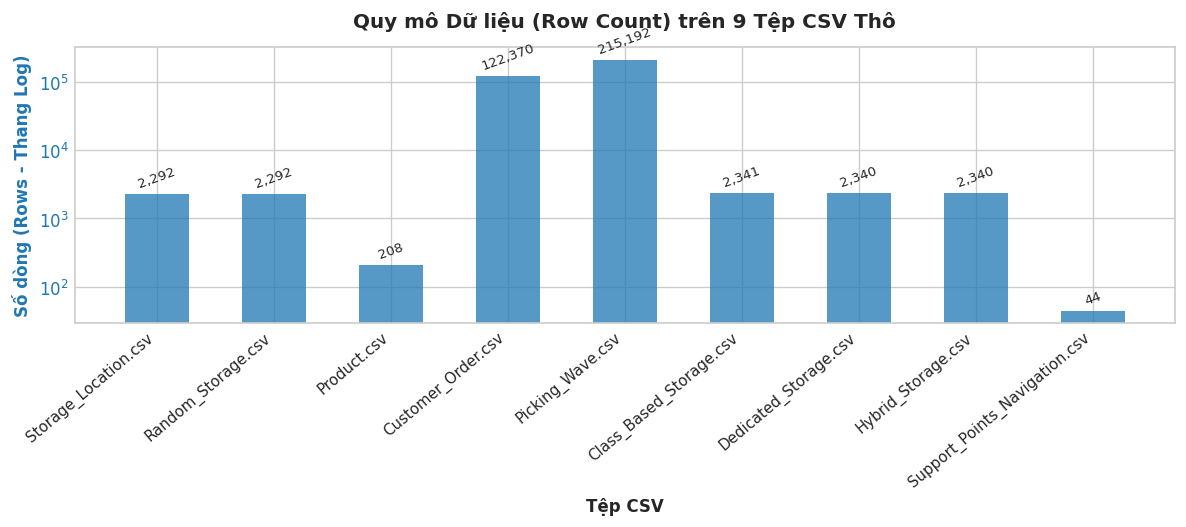

In [2]:
# Load data profile table
profile_df = pd.read_csv('../outputs/tables/data_profile.csv')
display(profile_df)

# Plot file sizes and row counts
fig, ax1 = plt.subplots(figsize=(10, 4.5))

color = 'tab:blue'
ax1.set_xlabel('Tệp CSV', fontweight='bold')
ax1.set_ylabel('Số dòng (Rows - Thang Log)', color=color, fontweight='bold')
bars = ax1.bar(profile_df['filename'], profile_df['rows'], color=color, alpha=0.75, width=0.55)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticklabels(profile_df['filename'], rotation=40, ha='right', fontsize=9)
ax1.set_yscale('log')

for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval * 1.15, f'{int(yval):,}', ha='center', va='bottom', fontsize=8, rotation=20)

plt.title('Quy mô Dữ liệu (Row Count) trên 9 Tệp CSV Thô', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 2. Phân bố Không gian theo Tầng Cao $z$ và Tọa độ Trùng

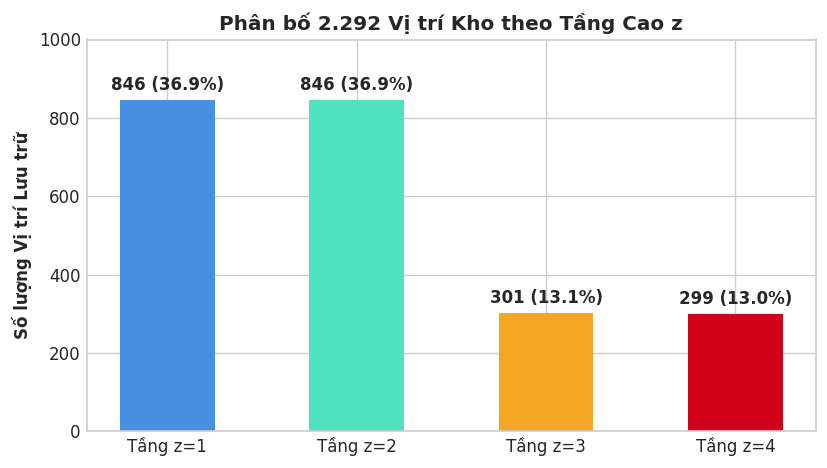

Số vị trí có tọa độ trùng: 2


,originalLocation,position,x,y,z
1190,K-23-30,"102, 810, 3",102,810,3
1191,K-23-40,"102, 810, 3",102,810,3


In [3]:
df_loc = load_raw_csv('Storage_Location.csv', raw_dir='../data/raw')
z_counts = df_loc['z'].value_counts().sort_index()

plt.figure(figsize=(7, 4))
colors = ['#4A90E2', '#50E3C2', '#F5A623', '#D0021B']
bars = plt.bar([f'Tầng z={int(z)}' for z in z_counts.index], z_counts.values, color=colors, width=0.5)
for bar in bars:
    yval = bar.get_height()
    pct = yval / len(df_loc) * 100
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f'{int(yval)} ({pct:.1f}%)', ha='center', va='bottom', fontweight='bold')

plt.ylabel('Số lượng Vị trí Lưu trữ', fontweight='bold')
plt.title('Phân bố 2.292 Vị trí Kho theo Tầng Cao z', fontsize=12, fontweight='bold')
plt.ylim(0, 1000)
plt.tight_layout()
plt.show()

# Check duplicate coordinates
coord_dups = df_loc[df_loc.duplicated(subset=['x', 'y', 'z'], keep=False)]
print(f"Số vị trí có tọa độ trùng: {len(coord_dups)}")
display(coord_dups[['originalLocation', 'position', 'x', 'y', 'z']])


## 3. Danh mục Sản phẩm & Phân loại ABC (`Product.csv`)

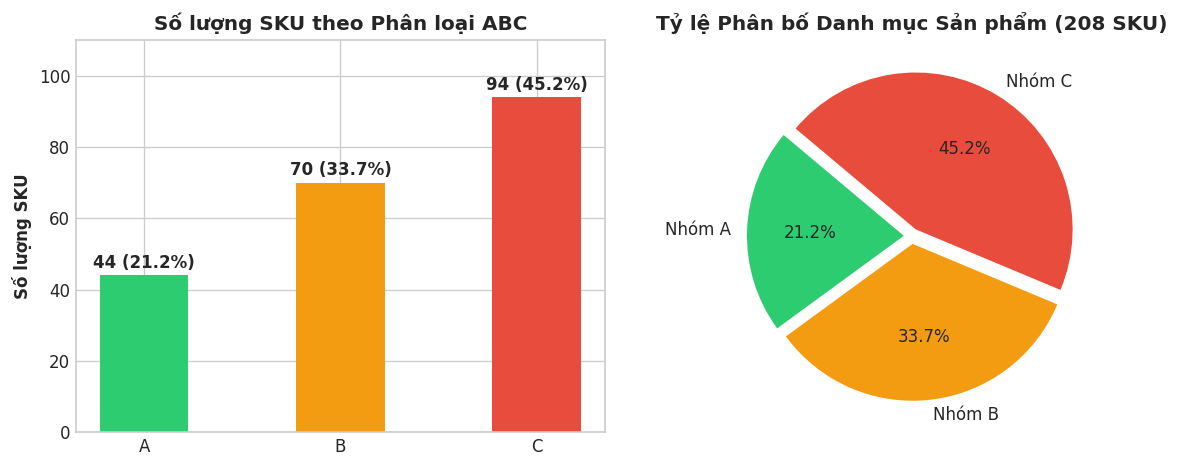

In [4]:
df_prod = load_raw_csv('Product.csv', raw_dir='../data/raw')
abc_counts = df_prod['ABCCOD'].value_counts().loc[['A', 'B', 'C']]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

colors_abc = ['#2ECC71', '#F39C12', '#E74C3C']
ax1.bar(abc_counts.index, abc_counts.values, color=colors_abc, width=0.45)
for i, v in enumerate(abc_counts.values):
    ax1.text(i, v + 2, f'{v} ({v/len(df_prod)*100:.1f}%)', ha='center', fontweight='bold')
ax1.set_ylabel('Số lượng SKU', fontweight='bold')
ax1.set_title('Số lượng SKU theo Phân loại ABC', fontweight='bold')
ax1.set_ylim(0, 110)

ax2.pie(abc_counts.values, labels=[f'Nhóm {k}' for k in abc_counts.index], autopct='%1.1f%%', colors=colors_abc, startangle=140, explode=(0.05, 0.05, 0.05))
ax2.set_title('Tỷ lệ Phân bố Danh mục Sản phẩm (208 SKU)', fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Mixing Index Baseline across Scopes & Biện luận Chốt Phạm vi

,scope_name,locations_count,total_slots,unique_references,average_mi,critical_locations_pct
0,"All Levels (z in {1, 2, 3, 4})",2292,41256,208,0.4362,47.69
1,Level z=1,846,15228,208,0.2692,29.43
2,Level z=2,846,15228,208,0.2646,28.96
3,Level z=3,301,5418,208,0.9131,99.67
4,Level z=4,299,5382,208,0.9142,100.00
5,"Candidate Scope (z in {3, 4})",600,10800,208,0.9136,99.83


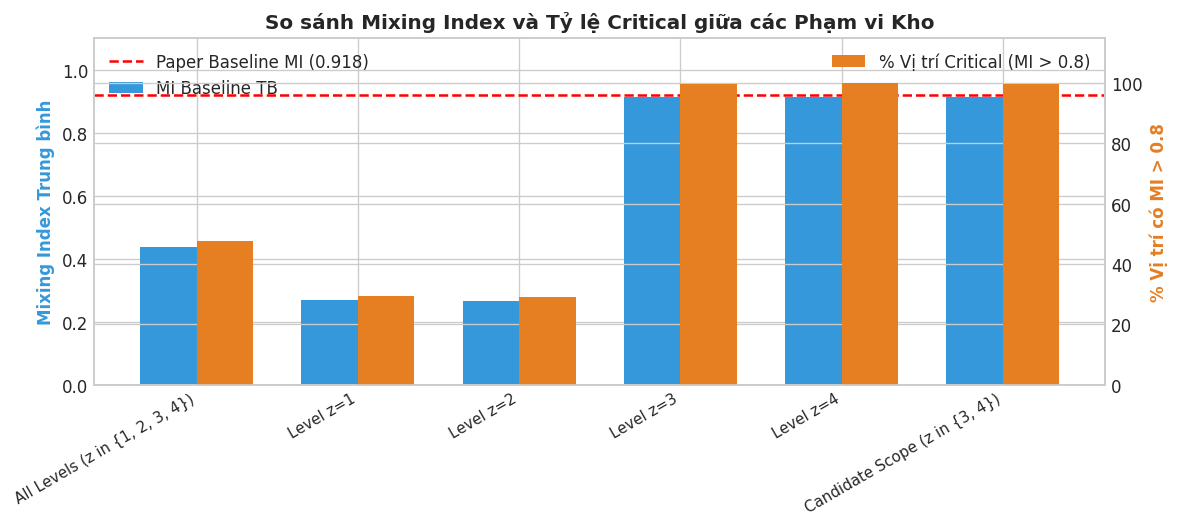

In [5]:
scope_df = pd.read_csv('../outputs/tables/baseline_mi_by_scope.csv')
display(scope_df[['scope_name', 'locations_count', 'total_slots', 'unique_references', 'average_mi', 'critical_locations_pct']])

fig, ax1 = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(scope_df))
width = 0.35

rects1 = ax1.bar(x - width/2, scope_df['average_mi'], width, label='MI Baseline TB', color='#3498DB')
ax1.set_ylabel('Mixing Index Trung bình', color='#3498DB', fontweight='bold')
ax1.set_ylim(0, 1.1)

ax2 = ax1.twinx()
rects2 = ax2.bar(x + width/2, scope_df['critical_locations_pct'], width, label='% Vị trí Critical (MI > 0.8)', color='#E67E22')
ax2.set_ylabel('% Vị trí có MI > 0.8', color='#E67E22', fontweight='bold')
ax2.set_ylim(0, 115)

ax1.set_xticks(x)
ax1.set_xticklabels(scope_df['scope_name'], rotation=30, ha='right', fontsize=9)
plt.title('So sánh Mixing Index và Tỷ lệ Critical giữa các Phạm vi Kho', fontweight='bold', fontsize=12)

ax1.axhline(0.918, color='red', linestyle='--', linewidth=1.5, label='Paper Baseline MI (0.918)')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()


## 5. Bảng Biện luận Chốt Phạm vi Chính ($z \in \{3, 4\}$)

In [6]:
just_df = pd.read_csv('../outputs/tables/scope_justification.csv')
display(just_df)


,Scope,Locations,SKUs,Slots_Per_Loc,Total_Slots,Size_Range,Baseline_MI,Critical_Rate_Pct,Assessment
0,"Paper Target (Assis et al., 2026)",847,209,18,15246,4.0 - 16.0,0.9180,100.00,Original reported benchmark in paper
1,Full Dataset (All z in {1..4}),2292,208,18,41256,4.0 - 280.0,0.4362,47.69,Mismatched size scale (mm/US) and dedicated zo...
2,"Candidate Scope z in {3, 4}",600,208,18,10800,4.0 - 16.0,0.9136,99.83,"RECOMMENDED: Exact size match, baseline MI wit..."
3,Sensitivity Scope z=3,301,208,18,5418,4.0 - 16.0,0.9131,99.67,Sub-floor sensitivity analysis
4,Sensitivity Scope z=4,299,208,18,5382,4.0 - 16.0,0.9142,100.00,Sub-floor sensitivity analysis
